# TED 02: limpeza, preparação e análise exploratória

A etapa está descrita nas seções 6 e 7 de `docs/JuriPredict_Documento_Tecnico_BigData.pdf`. Depende de `data/raw/`, preenchido pelo notebook da TED 01.

Este notebook executa `src/ted02_limpar_e_explorar.py`, que normaliza o texto, mascara nomes, documentos, OAB, datas, valores e números, remove processos duplicados e grava:

- `data/processed/processos.jsonl`: base tratada com o texto (não versionada);
- `resultados/ted02_resumo.json` e `resultados/ted02_base_tratada_metadados.csv`: estatísticas e metadados, sem texto;
- `resultados/figuras/`: gráficos da análise exploratória.

Em seguida roda os testes das regras de limpeza (`src/test_limpeza.py`).

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parents[1]
RESULTADOS = RAIZ / "resultados"
pd.set_option("display.float_format", lambda x: f"{x:.0f}" if float(x).is_integer() else f"{x:.4f}")


def rodar(*args):
    """Executa um comando Python a partir da raiz do repositório e informa quanto tempo levou."""
    inicio = time.time()
    r = subprocess.run([sys.executable, *args], cwd=RAIZ, capture_output=True, text=True, encoding="utf-8",
                       env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONDONTWRITEBYTECODE": "1"})
    if r.returncode:
        raise RuntimeError(r.stderr[-3000:])
    print(f"{' '.join(args)}: {(time.time() - inicio) / 60:.1f} min")
    return r.stdout


def figuras(*nomes):
    for nome in nomes:
        display(Image(filename=RESULTADOS / "figuras" / f"{nome}.png"))

In [2]:
rodar("src/ted02_limpar_e_explorar.py");

src/ted02_limpar_e_explorar.py: 12.7 min


In [3]:
print(rodar("-m", "pytest", "-q", "-p", "no:cacheprovider", "src/test_limpeza.py").strip().splitlines()[-1])

-m pytest -q -p no:cacheprovider src/test_limpeza.py: 0.1 min
7 passed in 3.43s


## Base antes e depois do tratamento

In [4]:
resumo = json.loads((RESULTADOS / "ted02_resumo.json").read_text(encoding="utf-8"))
pd.Series({k: resumo[k] for k in ["processos_brutos", "duplicados_removidos", "processos_finais",
                                  "movimentacoes_finais", "palavras_no_lexico_de_nomes"]}, name="quantidade")

processos_brutos                 6449
duplicados_removidos               86
processos_finais                 6363
movimentacoes_finais           539286
palavras_no_lexico_de_nomes     51337
Name: quantidade, dtype: int64

## Problemas de qualidade encontrados

Contagem de ocorrências por tipo. Os marcadores `tk*` indicam o que foi substituído no texto (`tknome`: nome de pessoa; `tkoab`: número de OAB; `tkdoc`: CPF ou CNPJ; `tkcnj`: número de processo).

In [5]:
pd.Series(resumo["problemas"], name="ocorrências")

com_nbsp_ou_controle        6621
acima_do_limite             5116
com_ano_invalido             736
tknome                    459511
tkcnj                       7810
tkdoc                       1549
tkoab                     254533
tkemail                      317
tkvalor                     5395
tkdata                    193053
tknum                     807894
vazias_apos_limpeza            0
repetidas_em_sequencia     11322
Name: ocorrências, dtype: int64

## Classes e origem

In [6]:
pd.DataFrame(resumo["origem_x_classe"])

,arquivado,ativo,suspenso
RJ (provável),328,183,0
SP (provável),2677,2685,490


In [7]:
print("V de Cramér entre origem e classe:", resumo["cramer_v_origem_classe"])
pd.DataFrame(resumo["descritivas_gerais"])

V de Cramér entre origem e classe: 0.117


,n_mov,chars_total,chars_medio,ano_ref
count,6363,6363,6363,5778
mean,84.8000,12199.7000,152.2000,2017.3000
std,91.8000,13687.3000,49.5000,1.5000
min,1,77,25.1000,2003
25%,36,5332,120.5000,2016
50%,60,8985,147.2000,2018
75%,110,15291.5000,178.5000,2018
max,2659,503574,563.6000,2021


In [8]:
pd.DataFrame(resumo["kruskal_wallis"]).T

,H,p,eta2
n_mov,152.1000,0.0000,0.0236
chars_total,157.2000,0.0000,0.0244
chars_medio,11.8000,0.0027,0.0015


## Gráficos

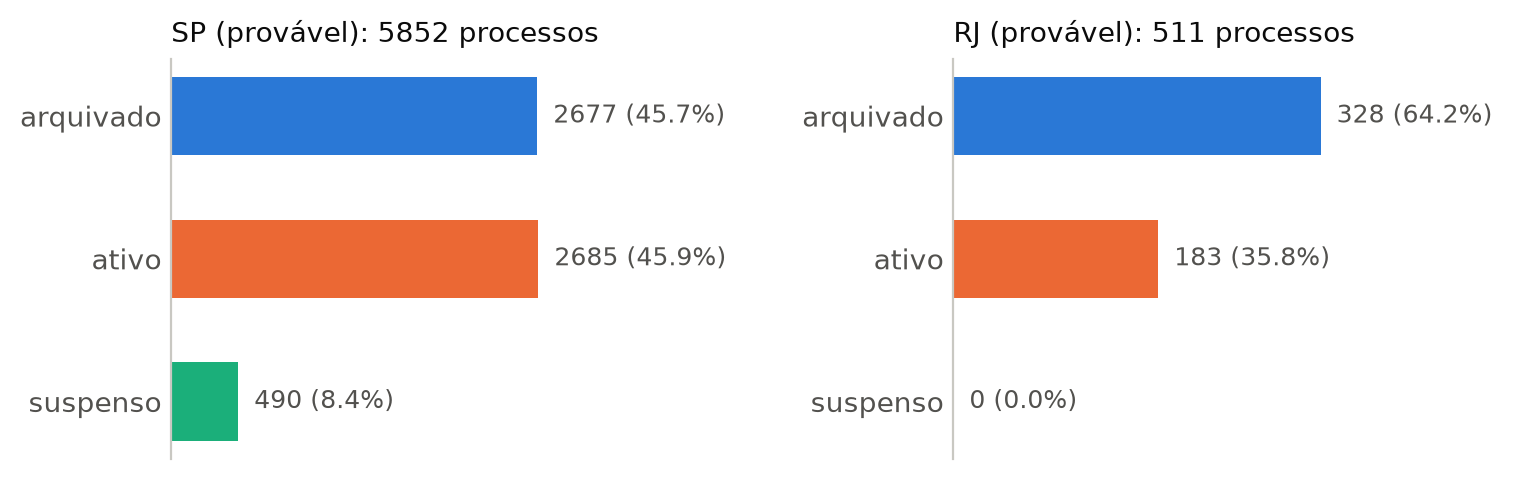

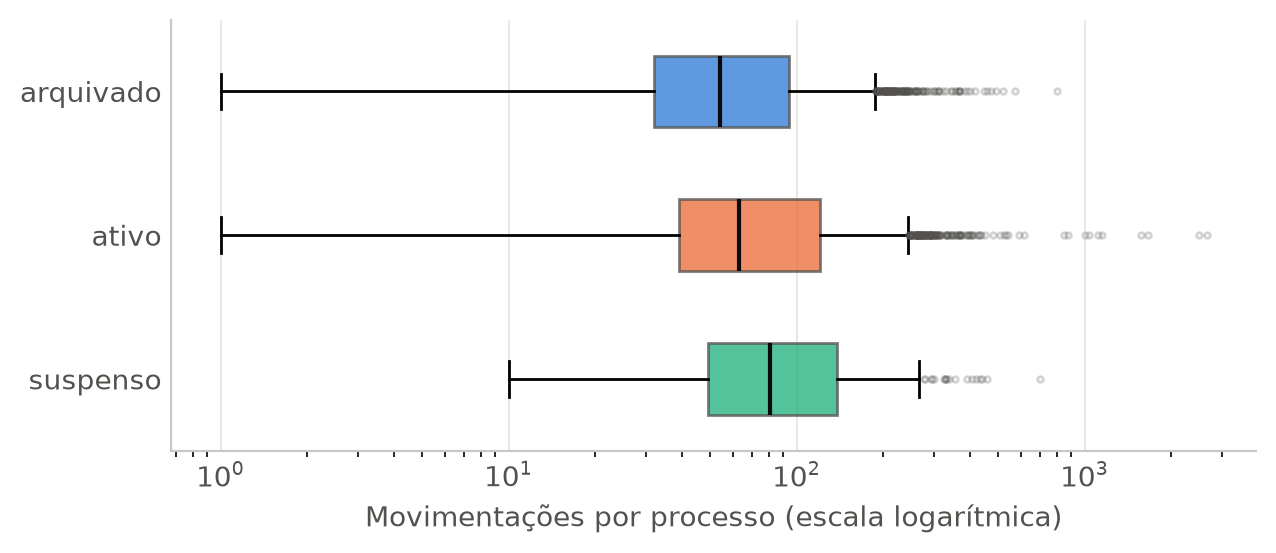

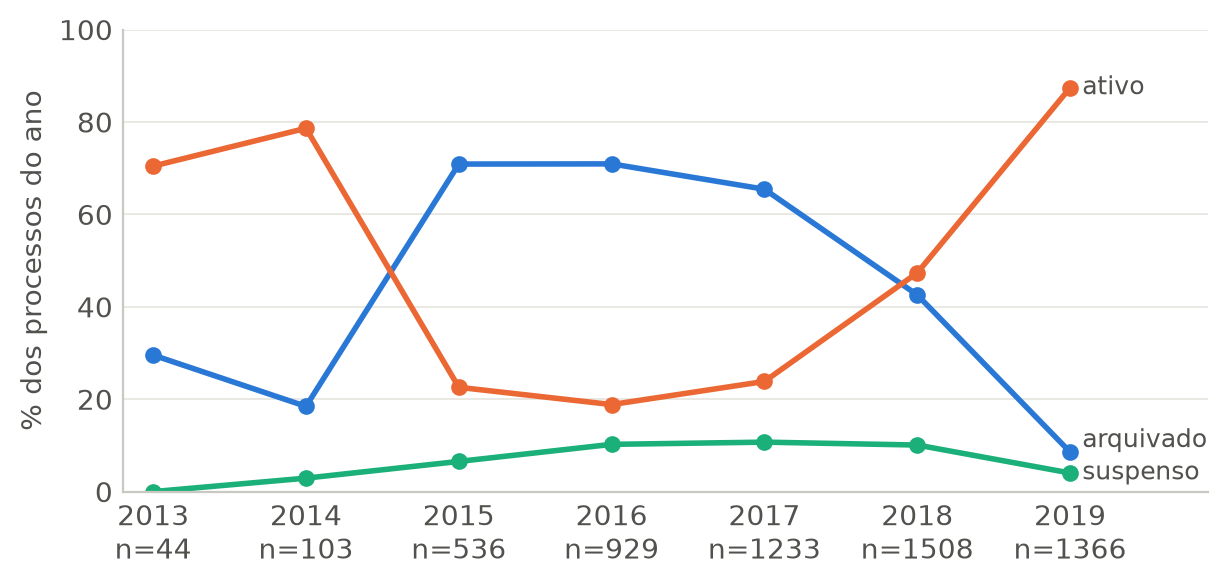

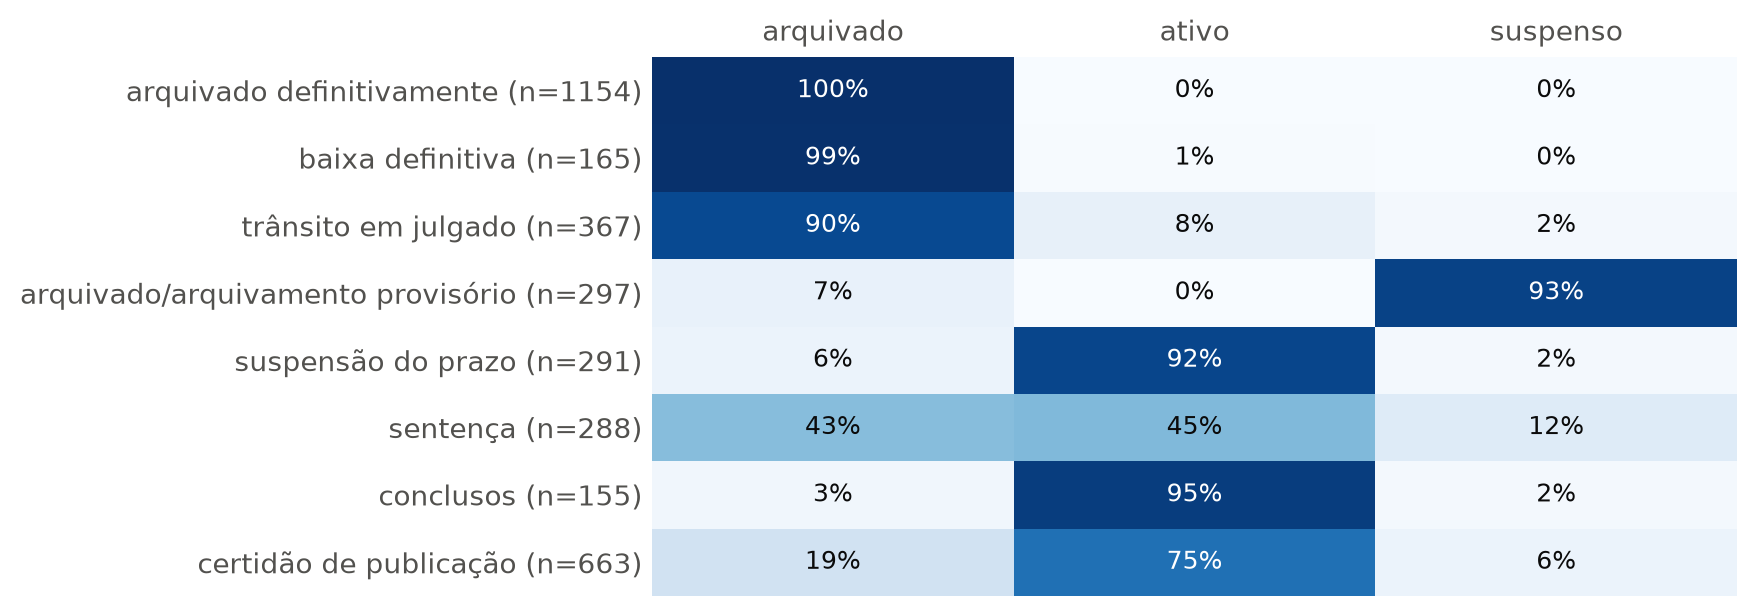

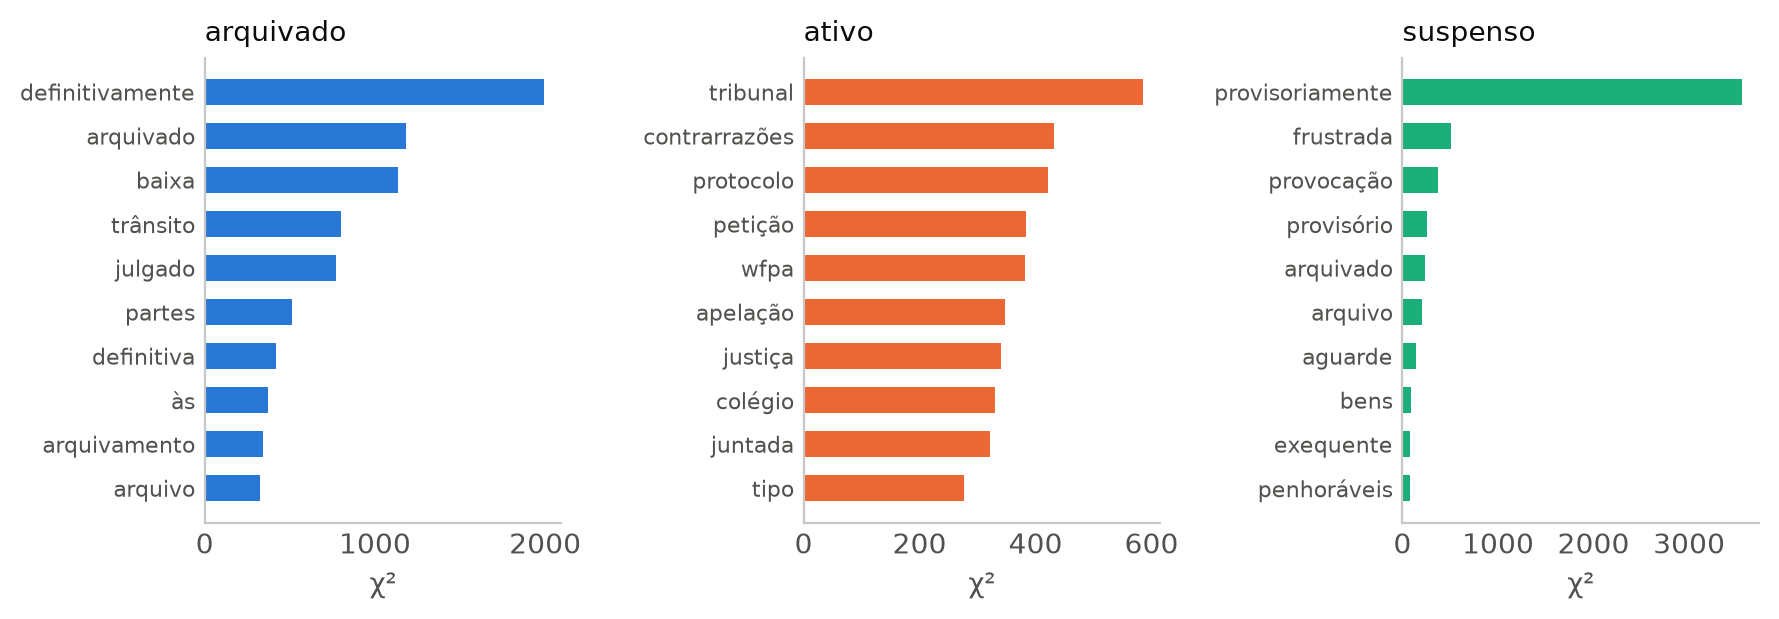

In [9]:
figuras("fig_classes_origem", "fig_n_mov", "fig_anos", "fig_expressoes", "fig_termos")